**0단계 - 파일 업로드**

In [19]:
from google.colab import files
uploaded = files.upload()
# 다음 5개 파일을 한번에 선택해서 업로드하세요
# 1) 국토교통부_전국 버스정류장 위치정보 (csv)
# 2) 서울시 버스정류소 위치정보 (csv)
# 3) 농림어업총조사 지역조사 3종 (xlsx, 3개)
# 4) KOSIS 연령 및 성별 인구 - 읍면동 (xlsx)
# 5) KOSIS 인구,가구및주택 - 읍면동 (xlsx)
# 6) 한국교통안전공단 지역별 차종별 온실가스 배출량 (csv)

Saving 교통∙안전시설_소재지_및_소요시간별_행정리_20260913220920.xlsx to 교통∙안전시설_소재지_및_소요시간별_행정리_20260913220920 (1).xlsx
Saving 국토교통부_전국 버스정류장 위치정보_20251031.csv to 국토교통부_전국 버스정류장 위치정보_20251031 (1).csv
Saving 대중교통_운행횟수별_행정리_수_20260913220724.xlsx to 대중교통_운행횟수별_행정리_수_20260913220724 (1).xlsx
Saving 서울시 버스정류소 위치정보.csv to 서울시 버스정류소 위치정보 (1).csv
Saving 시내버스_정류장과의_거리별_행정리_20260913220903.xlsx to 시내버스_정류장과의_거리별_행정리_20260913220903 (1).xlsx
Saving 연령_및_성별_인구_–_읍면동_20260914133937.xlsx to 연령_및_성별_인구_–_읍면동_20260914133937 (1).xlsx
Saving 인구__가구_및_주택_–_읍면동_연도_끝자리_0__5___시군구_그_외_연도__20260914134045.xlsx to 인구__가구_및_주택_–_읍면동_연도_끝자리_0__5___시군구_그_외_연도__20260914134045 (1).xlsx
Saving 한국교통안전공단_지역별 차종별도로부문 온실가스 배출량_20241231.csv to 한국교통안전공단_지역별 차종별도로부문 온실가스 배출량_20241231 (1).csv


**1단계 - 실제 구조 확인**

In [20]:
import pandas as pd

def load_csv_robust(path):
    for enc in ['utf-8-sig', 'cp949', 'euc-kr']:
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"인코딩 실패: {path}")

# --- 파일명은 실제 업로드한 이름으로 바꿔주세요 ---
bus_national = load_csv_robust('국토교통부_전국 버스정류장 위치정보_20251031.csv')
bus_seoul    = load_csv_robust('서울시 버스정류소 위치정보.csv')
ghg          = load_csv_robust('한국교통안전공단_지역별 차종별도로부문 온실가스 배출량_20241231.csv')

print("=== 전국 버스정류장 ===", bus_national.shape)
display(bus_national.head(3))
print("=== 서울 버스정류장 ===", bus_seoul.shape)
display(bus_seoul.head(3))
print("=== 온실가스 배출량 ===", ghg.shape)
display(ghg.head(3))

# KOSIS/농림어업총조사 엑셀은 헤더가 몇 줄인지 모르니 헤더 없이 raw로 먼저 열어봅니다
age_raw   = pd.read_excel('연령_및_성별_인구_–_읍면동_20260914133937.xlsx', header=None)
house_raw = pd.read_excel('인구__가구_및_주택_–_읍면동_연도_끝자리_0__5___시군구_그_외_연도__20260914134045.xlsx', header=None)
farm1_raw = pd.read_excel('대중교통_운행횟수별_행정리_수_20260913220724.xlsx', header=None)
farm2_raw = pd.read_excel('시내버스_정류장과의_거리별_행정리_20260913220903.xlsx', header=None)
farm3_raw = pd.read_excel('교통∙안전시설_소재지_및_소요시간별_행정리_20260913220920.xlsx', header=None)

for name, df in [('연령인구', age_raw), ('가구주택', house_raw),
                  ('농림1_운행횟수', farm1_raw), ('농림2_거리', farm2_raw), ('농림3_소요시간', farm3_raw)]:
    print(f"\n=== {name} (상위 8행) ===")
    display(df.head(8))

=== 전국 버스정류장 === (227065, 9)


,정류장번호,정류장명,위도,경도,정보수집일,모바일단축번호,도시코드,도시명,관리도시명
0,ADB354000001,길안정류장,36.458658,128.891228,2025-10-31,540001.0,37040,경상북도 안동시,안동BIS
1,ADB354000002,고란.계명산휴양림입구,36.397708,128.924029,2025-10-31,540002.0,37040,경상북도 안동시,안동BIS
2,ADB354000003,금곡리,36.397504,128.926821,2025-10-31,540003.0,37040,경상북도 안동시,안동BIS


=== 서울 버스정류장 === (11236, 6)


,노드 ID,정류소번호,정류소명,X좌표,Y좌표,정류소 타입
0,1,123000689,한강버스.잠실선착장,127.084778,37.518944,한강선착장
1,2,104000315,한강버스.뚝섬선착장,127.066472,37.528695,한강선착장
2,3,103000517,한강버스.옥수선착장,127.018056,37.538750,한강선착장


=== 온실가스 배출량 === (221, 6)


...

,0,1,2,3,4,5,6,7,8,9,...,19,20,21,22,23,24,25,26,27,28
0,행정구역별,2020,2020,2020,2020,2020,2020,2020,2020,2020,...,2020,2020,2020,2020,2020,2020,2020,2020,2020,2020
1,행정구역별,총행정리수 (행정리),대중교통운행 (행정리),"시내(군내,마을)버스:운행 (행정리)",10회미만_1~3 (행정리),10회미만_4~6 (행정리),10회미만_7~9 (행정리),10~15 (행정리),15회이상 (행정리),시외버스:운행 (행정리),...,10~15 (행정리),15회이상 (행정리),여객선(유선·도선포함):운행 (행정리),10회미만_1~3 (행정리),10회미만_4~6 (행정리),10회미만_7~9 (행정리),10~15 (행정리),15회이상 (행정리),농어촌 교통수단 운행 (행정리),농어촌 교통수단 미운행 (행정리)
2,전국,37563,35339,34925,5411,10485,3661,5510,9858,3622,...,197,169,431,269,89,34,12,27,1691,533
3,읍부,9456,8979,8875,826,1583,606,1250,4610,1480,...,151,123,112,58,22,9,4,19,276,201
4,면부,28107,26360,26050,4585,8902,3055,4260,5248,2142,...,46,46,319,211,67,25,8,8,1415,332
5,부산광역시,186,184,184,7,24,6,20,127,5,...,2,4,2,2,-,-,-,-,-,2
6,대구광역시,314,284,284,5,20,11,48,200,6,...,-,-,-,-,-,-,-,-,22,8
7,인천광역시,266,197,190,3,24,25,34,104,33,...,-,-,8,6,-,-,-,2,56,13



=== 농림2_거리 (상위 8행) ===


,0,1,2,3,4,5,6,7,8
0,행정구역별,2020,2020,2020,2020,2020,2020,2020,2020
1,행정구역별,총행정리수 (행정리),시내버스 정류장 있는 행정리 (행정리),250m 미만 (행정리),250m~500m (행정리),500m~1km (행정리),1km~2km (행정리),2km 이상 (행정리),시내버스 정류장 없는 행정리 (행정리)
2,전국,37563,36687,17147,10493,7285,1150,612,876
3,읍부,9456,9248,4360,2763,1752,240,133,208
4,면부,28107,27439,12787,7730,5533,910,479,668
5,부산광역시,186,184,95,59,30,-,-,2
6,대구광역시,314,310,130,92,62,15,11,4
7,인천광역시,266,195,104,30,56,4,1,71



=== 농림3_소요시간 (상위 8행) ===


,0,1,2,3,4,5,6,7,8,9,...,28,29,30,31,32,33,34,35,36,37
0,행정구역별,2020,2020,2020,2020,2020,2020,2020,2020,2020,...,2020,2020,2020,2020,2020,2020,2020,2020,2020,2020
1,행정구역별,총행정리수 (행정리),시외버스터미널(간이정류장포함):행정리내 (행정리),읍∙면내 (행정리),읍∙면외 다른 지역_10분미만 (행정리),10~19 (행정리),20~29 (행정리),30~39 (행정리),40~49 (행정리),50~59 (행정리),...,60분이상 (행정리),"파출소(지구대,치안센터포함):행정리내 (행정리)",읍∙면내 (행정리),읍∙면외 다른 지역_10분미만 (행정리),10~19 (행정리),20~29 (행정리),30~39 (행정리),40~49 (행정리),50~59 (행정리),60분이상 (행정리)
2,전국,37563,2620,15507,472,4947,6407,4985,1423,372,...,124,2860,32881,76,797,585,292,46,7,19
3,읍부,9456,747,6105,70,389,826,855,274,93,...,11,648,8644,5,75,59,19,2,1,3
4,면부,28107,1873,9402,402,4558,5581,4130,1149,279,...,113,2212,24237,71,722,526,273,44,6,16
5,부산광역시,186,10,94,-,3,26,48,4,-,...,-,16,168,-,2,-,-,-,-,-
6,대구광역시,314,1,40,13,27,58,60,104,7,...,-,37,277,-,-,-,-,-,-,-
7,인천광역시,266,34,72,7,33,16,32,7,-,...,2,53,205,3,-,4,1,-,-,-


**2단계 - 시군구 표준화**

In [40]:
SIDO_NAMES = {
    '서울특별시','부산광역시','대구광역시','인천광역시','광주광역시','대전광역시','울산광역시',
    '세종특별자치시','경기도','강원특별자치도','충청북도','충청남도','전북특별자치도',
    '전라남도','경상북도','경상남도','제주특별자치도'
}
SIDO_ALIASES = {'강원도':'강원특별자치도','전라북도':'전북특별자치도'}
NON_REGION = {'전국','동부','읍부','면부'}
GU_HAVING_CITIES = {'수원시','성남시','안양시','안산시','고양시','용인시',
                     '청주시','천안시','전주시','포항시','창원시','부천시'}


def build_sigungu_keys(raw_names):
    """행정구역별 원본 이름을 행 순서 그대로 받아서,
       진짜 시군구 합계 행에만 '시도 시군구' 키를 주고
       (전국/동부·읍부·면부, 시도총계행, 읍면동 상세행, 특례시 하위구)는 None을 반환한다.
       ※ 수정: 동부/읍부/면부는 전국 밑뿐 아니라 각 시도 밑에도 반복 등장하므로,
          이걸 만나도 cur_sido를 리셋하지 않도록 수정함 (이전 버전은 여기서 시도 정보를
          잃어버려 시군구 대부분이 누락되는 버그가 있었음)"""
    keys = []
    cur_sido = None
    skip_sub_gu = False
    for raw in raw_names:
        if pd.isna(raw):
            keys.append(None)
            continue
        name = str(raw).strip()
        if name in NON_REGION:
            keys.append(None)   # cur_sido는 그대로 유지 (리셋하지 않음)
            continue
        canon = SIDO_ALIASES.get(name, name)
        if canon in SIDO_NAMES:
            cur_sido, skip_sub_gu = canon, False
            keys.append(None)   # 시도 총계행 자체는 제외
            continue
        if skip_sub_gu and name.endswith('구'):
            keys.append(None)   # 특례시 하위 구 -> 제외
            continue
        skip_sub_gu = False
        if name.endswith(('시','군','구')):
            if name in GU_HAVING_CITIES:
                skip_sub_gu = True
            keys.append(f"{cur_sido} {name}" if cur_sido else None)
            continue
        keys.append(None)   # 읍면동 이하 상세행 -> 제외
    return keys


# TAGO 파일(bus_national)용 - 한 칸에 '시도 시군구'가 이미 붙어있는 형식
def normalize_sigungu(full_name: str) -> str:
    if pd.isna(full_name):
        return None
    tokens = str(full_name).strip().split()
    if not tokens:
        return None
    sido = SIDO_ALIASES.get(tokens[0], tokens[0])
    if '세종' in sido:
        return sido
    if len(tokens) < 2:
        return sido
    sigungu = tokens[1]
    for city in GU_HAVING_CITIES:
        if sigungu.startswith(city):
            return f"{sido} {city}"
    return f"{sido} {sigungu}"

**3단계 - 정류장 데이터 결합**

In [22]:
bus_national['sigungu'] = bus_national['도시명'].apply(normalize_sigungu)

# 서울 파일: 자치구 구분이 없어서 전체를 '서울특별시' 한 단위로 처리
# 한강선착장은 버스정류소가 아니라 선착장이라 제외하는 걸 추천
bus_seoul_clean = bus_seoul[bus_seoul['정류소 타입'] != '한강선착장'].copy()
bus_seoul_clean['sigungu'] = '서울특별시'

stop_count = pd.concat([
    bus_national[['sigungu']],
    bus_seoul_clean[['sigungu']]
]).groupby('sigungu').size().reset_index(name='정류장수')

print(stop_count.sort_values('정류장수').head(10))
print(stop_count.sort_values('정류장수', ascending=False).head(10))

         sigungu  정류장수
59      경상남도 진해시     1
154     충청북도 증평군     1
103     전라남도 담양군     2
4    강원특별자치도 양구군     2
1    강원특별자치도 동해시     4
52      경상남도 마산시     8
141     충청남도 연기군     8
124  전북특별자치도 완주군    14
125  전북특별자치도 익산시    15
0    강원특별자치도 강릉시    20
      sigungu   정류장수
94      서울특별시  28208
93      부산광역시   9975
97      인천광역시   9278
90      대구광역시   5937
67   경상북도 경산시   4629
131   제주특별자치도   4300
89      광주광역시   4267
96      울산광역시   3960
61   경상남도 창원시   3518
157  충청북도 청주시   3451


**4단계 - 고령인구비율**

In [42]:
from google.colab import files
uploaded = files.upload()   # 여기서 '101_DT_1IN1503_20260914162447.xls' 파일 선택해서 업로드
print(list(uploaded.keys()))  # 실제 업로드된 파일명 확인

Saving 101_DT_1IN1503_20260914162447.xls to 101_DT_1IN1503_20260914162447.xls
['101_DT_1IN1503_20260914162447.xls']


In [43]:
import xml.etree.ElementTree as ET

def read_kosis_xml_xls(path):
    """KOSIS에서 받은 '.xls'가 실제로는 SpreadsheetML(엑셀 XML) 포맷이라
       pandas.read_excel로 못 엶 -> 직접 XML 파싱"""
    with open(path, 'rb') as f:
        raw = f.read()
    text = raw.decode('euc-kr', errors='replace').lstrip()
    text = text.replace('encoding="EUC-KR"', 'encoding="UTF-8"')
    # '메타정보' 시트에 이스케이프 안 된 '<' 문자가 있어 전체 파싱시 에러남 -> 데이터 시트까지만 자름
    idx = text.find('메타정보')
    if idx != -1:
        idx2 = text.rfind('<Worksheet', 0, idx)
        text = text[:idx2] + '</Workbook>'
    root = ET.fromstring(text)
    ns = '{urn:schemas-microsoft-com:office:spreadsheet}'
    rows_out = []
    for ws in root.findall(f'{ns}Worksheet'):
        table = ws.find(f'{ns}Table')
        if table is None:
            continue
        for row in table.findall(f'{ns}Row'):
            cells = []
            for cell in row.findall(f'{ns}Cell'):
                data = cell.find(f'{ns}Data')
                cells.append(data.text if data is not None else None)
            rows_out.append(cells)
    return rows_out

raw_rows = read_kosis_xml_xls('101_DT_1IN1503_20260914162447.xls')
data_rows = [r for r in raw_rows[2:] if r and len(r) >= 5]
long_df = pd.DataFrame(data_rows, columns=['행정구역_raw', '연령별', '항목', '단위', '2025'])
long_df['2025'] = pd.to_numeric(long_df['2025'], errors='coerce')

long_df['sigungu'] = build_sigungu_keys(long_df['행정구역_raw'])
long_valid = long_df[long_df['sigungu'].notna()].copy()

total_pop = (long_valid[(long_valid['연령별'] == '합계') & (long_valid['항목'] == '총인구(명)')]
             .groupby('sigungu')['2025'].sum().reset_index(name='전체인구'))
elderly = (long_valid[(long_valid['연령별'] == '65세이상') & (long_valid['항목'] == '총인구(명)')]
           .groupby('sigungu')['2025'].sum().reset_index(name='고령인구'))

age_sigungu = total_pop.merge(elderly, on='sigungu', how='left')
age_sigungu['고령인구비율'] = age_sigungu['고령인구'] / age_sigungu['전체인구']

print(age_sigungu.shape)                              # (229, 4) 근처가 나와야 정상
print('전체인구 합:', age_sigungu['전체인구'].sum())     # 51,817,499 근처가 나와야 정상
age_sigungu.head(10)

(229, 4)
전체인구 합: 51817499.0


,sigungu,전체인구,고령인구,고령인구비율
0,강원특별자치도 강릉시,211628.0,56024.0,0.264729
1,강원특별자치도 고성군,27706.0,9051.0,0.326680
2,강원특별자치도 동해시,84564.0,22614.0,0.267419
3,강원특별자치도 삼척시,62105.0,18814.0,0.302939
4,강원특별자치도 속초시,78972.0,20190.0,0.255660
5,강원특별자치도 양구군,20299.0,5532.0,0.272526
6,강원특별자치도 양양군,26544.0,9701.0,0.365469
7,강원특별자치도 영월군,35094.0,13211.0,0.376446
8,강원특별자치도 원주시,367326.0,72824.0,0.198254
9,강원특별자치도 인제군,30469.0,8015.0,0.263054


** 가구주택 파일에서 1인가구 컬럼이 정확히 몇 번째, 이름이 뭔지 확인

In [24]:
house_raw = pd.read_excel('인구__가구_및_주택_–_읍면동_연도_끝자리_0__5___시군구_그_외_연도__20260914134045.xlsx', header=None)
year_row2 = house_raw.iloc[0]
item_row2 = house_raw.iloc[1]
new_cols2 = []
for y, item in zip(year_row2, item_row2):
    y = '' if pd.isna(y) else str(y).strip()
    item = '' if pd.isna(item) else str(item).strip()
    new_cols2.append(f"{y}_{item}" if y.isdigit() else item)

house = house_raw.iloc[2:].copy()
house.columns = new_cols2
house = house.reset_index(drop=True)

print(house.shape)
for c in house.columns:
    print(c)   # 전체 컬럼명을 다 출력 - '1인가구'가 들어간 컬럼 찾기

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


(329, 61)
행정구역별(읍면동)
2015_총인구 (명)
2015_남자 (명)
2015_여자 (명)
2015_내국인_계 (명)
2015_내국인_남자 (명)
2015_내국인_여자 (명)
2015_외국인_계 (명)
2015_외국인_남자 (명)
2015_외국인_여자 (명)
2015_가구_계 (가구)
2015_일반가구 (가구)
2015_집단가구 (가구)
2015_외국인가구 (가구)
2015_주택_계 (호)
2015_주택_단독주택 (호)
2015_주택_아파트 (호)
2015_주택_연립주택 (호)
2015_주택_다세대주택 (호)
2015_주택_비주거용 건물 내 주택 (호)
2015_주택 이외의 거처_계 (호)
2020_총인구 (명)
2020_남자 (명)
2020_여자 (명)
2020_내국인_계 (명)
2020_내국인_남자 (명)
2020_내국인_여자 (명)
2020_외국인_계 (명)
2020_외국인_남자 (명)
2020_외국인_여자 (명)
2020_가구_계 (가구)
2020_일반가구 (가구)
2020_집단가구 (가구)
2020_외국인가구 (가구)
2020_주택_계 (호)
2020_주택_단독주택 (호)
2020_주택_아파트 (호)
2020_주택_연립주택 (호)
2020_주택_다세대주택 (호)
2020_주택_비주거용 건물 내 주택 (호)
2020_주택 이외의 거처_계 (호)
2025_총인구 (명)
2025_남자 (명)
2025_여자 (명)
2025_내국인_계 (명)
2025_내국인_남자 (명)
2025_내국인_여자 (명)
2025_외국인_계 (명)
2025_외국인_남자 (명)
2025_외국인_여자 (명)
2025_가구_계 (가구)
2025_일반가구 (가구)
2025_집단가구 (가구)
2025_외국인가구 (가구)
2025_주택_계 (호)
2025_주택_단독주택 (호)
2025_주택_아파트 (호)
2025_주택_연립주택 (호)
2025_주택_다세대주택 (호)
2025_주택_비주거용 건물 내 주택 (호)
2025_주택 이외의 거처_계 (호)


In [34]:
house_raw = pd.read_excel('인구__가구_및_주택_–_읍면동_연도_끝자리_0__5___시군구_그_외_연도__20260914134045.xlsx', header=None)
year_row2 = house_raw.iloc[0]
item_row2 = house_raw.iloc[1]
new_cols2 = []
for y, item in zip(year_row2, item_row2):
    y = '' if pd.isna(y) else str(y).strip()
    item = '' if pd.isna(item) else str(item).strip()
    new_cols2.append(f"{y}_{item}" if y.isdigit() else item)

house = house_raw.iloc[2:].copy()
house.columns = new_cols2
house = house.reset_index(drop=True)

region_col = house.columns[0]
pop_col    = '2025_총인구 (명)'
hh_col     = '2025_가구_계 (가구)'

house[pop_col] = pd.to_numeric(house[pop_col], errors='coerce')
house[hh_col]  = pd.to_numeric(house[hh_col], errors='coerce')
house['평균가구원수'] = house[pop_col] / house[hh_col]

house_raw = pd.read_excel('인구__가구_및_주택_–_읍면동_연도_끝자리_0__5___시군구_그_외_연도__20260914134045.xlsx', header=None)
year_row2 = house_raw.iloc[0]
item_row2 = house_raw.iloc[1]
new_cols2 = []
for y, item in zip(year_row2, item_row2):
    y = '' if pd.isna(y) else str(y).strip()
    item = '' if pd.isna(item) else str(item).strip()
    new_cols2.append(f"{y}_{item}" if y.isdigit() else item)

house = house_raw.iloc[2:].copy()
house.columns = new_cols2
house = house.reset_index(drop=True)

region_col = house.columns[0]
pop_col    = '2025_총인구 (명)'
hh_col     = '2025_가구_계 (가구)'

house[pop_col] = pd.to_numeric(house[pop_col], errors='coerce')
house[hh_col]  = pd.to_numeric(house[hh_col], errors='coerce')

# 여기가 핵심 수정 부분: normalize_sigungu 대신 build_sigungu_keys 사용
house['sigungu'] = build_sigungu_keys(house[region_col])
house_valid = house[house['sigungu'].notna()].copy()

house_sigungu = house_valid.groupby('sigungu').agg(
    총인구=(pop_col, 'sum'),
    가구계=(hh_col, 'sum')
).reset_index()
house_sigungu['평균가구원수'] = house_sigungu['총인구'] / house_sigungu['가구계']

print(house_sigungu.shape)   # age_sigungu와 비슷하게 250개 안팎이어야 정상
house_sigungu.sort_values('평균가구원수').head(10)
house_sigungu = house.groupby('sigungu').agg(
    총인구=(pop_col, 'sum'),
    가구계=(hh_col, 'sum')
).reset_index()
house_sigungu['평균가구원수'] = house_sigungu['총인구'] / house_sigungu['가구계']

house_sigungu.sort_values('평균가구원수').head(10)   # 값이 작을수록 소규모가구 많은 지역

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


(35, 4)


,sigungu,총인구,가구계,평균가구원수
14,서울특별시 관악구,492225.0,282631.0,1.741582
33,서울특별시 중구,123946.0,64423.0,1.923940
17,서울특별시 금천구,241253.0,124499.0,1.937791
15,서울특별시 광진구,345302.0,172000.0,2.007570
32,서울특별시 종로구,143114.0,70966.0,2.016656
2,광주광역시 동구,110816.0,54425.0,2.036123
30,서울특별시 용산구,200742.0,98220.0,2.043800
29,서울특별시 영등포구,398576.0,194893.0,2.045102
20,서울특별시 동대문구,360046.0,175714.0,2.049046
22,서울특별시 마포구,354962.0,172789.0,2.054309


In [46]:
import inspect
print(inspect.getsource(build_sigungu_keys))

def build_sigungu_keys(raw_names):
    """행정구역별 원본 이름을 행 순서 그대로 받아서,
       진짜 시군구 합계 행에만 '시도 시군구' 키를 주고
       (전국/동부·읍부·면부, 시도총계행, 읍면동 상세행, 특례시 하위구)는 None을 반환한다.
       ※ 수정: 동부/읍부/면부는 전국 밑뿐 아니라 각 시도 밑에도 반복 등장하므로,
          이걸 만나도 cur_sido를 리셋하지 않도록 수정함 (이전 버전은 여기서 시도 정보를
          잃어버려 시군구 대부분이 누락되는 버그가 있었음)"""
    keys = []
    cur_sido = None
    skip_sub_gu = False
    for raw in raw_names:
        if pd.isna(raw):
            keys.append(None)
            continue
        name = str(raw).strip()
        if name in NON_REGION:
            keys.append(None)   # cur_sido는 그대로 유지 (리셋하지 않음)
            continue
        canon = SIDO_ALIASES.get(name, name)
        if canon in SIDO_NAMES:
            cur_sido, skip_sub_gu = canon, False
            keys.append(None)   # 시도 총계행 자체는 제외
            continue
        if skip_sub_gu and name.endswith('구'):
            keys.append(None)   # 특례시 하위 구 -> 제외
            continue
        skip_sub_gu = False
        if name.endswith(('시','군','구'))

In [47]:
keys = build_sigungu_keys(house[region_col])
print('None 개수:', sum(k is None for k in keys))
print('유효한(None 아닌) 개수:', sum(k is not None for k in keys))

house['sigungu'] = keys
house_valid = house[house['sigungu'].notna()].copy()
print('house_valid 행 수:', len(house_valid))
print('house_valid 고유 sigungu 개수:', house_valid['sigungu'].nunique())
print(house_valid['sigungu'].unique()[:40])

None 개수: 98
유효한(None 아닌) 개수: 231
house_valid 행 수: 231
house_valid 고유 sigungu 개수: 231
['서울특별시 종로구' '서울특별시 중구' '서울특별시 용산구' '서울특별시 성동구' '서울특별시 광진구' '서울특별시 동대문구'
 '서울특별시 중랑구' '서울특별시 성북구' '서울특별시 강북구' '서울특별시 도봉구' '서울특별시 노원구' '서울특별시 은평구'
 '서울특별시 서대문구' '서울특별시 마포구' '서울특별시 양천구' '서울특별시 강서구' '서울특별시 구로구' '서울특별시 금천구'
 '서울특별시 영등포구' '서울특별시 동작구' '서울특별시 관악구' '서울특별시 서초구' '서울특별시 강남구' '서울특별시 송파구'
 '서울특별시 강동구' '부산광역시 중구' '부산광역시 서구' '부산광역시 동구' '부산광역시 영도구' '부산광역시 부산진구'
 '부산광역시 동래구' '부산광역시 남구' '부산광역시 북구' '부산광역시 해운대구' '부산광역시 사하구' '부산광역시 금정구'
 '부산광역시 강서구' '부산광역시 연제구' '부산광역시 수영구' '부산광역시 사상구']


In [48]:
house_sigungu = house_valid.groupby('sigungu').agg(
    총인구=(pop_col, 'sum'), 가구계=(hh_col, 'sum')
).reset_index()
house_sigungu['평균가구원수'] = house_sigungu['총인구'] / house_sigungu['가구계']

print(house_sigungu.shape)
house_sigungu.head(10)

(231, 4)


,sigungu,총인구,가구계,평균가구원수
0,강원특별자치도 강릉시,211628.0,101874.0,2.077350
1,강원특별자치도 고성군,27706.0,13493.0,2.053361
2,강원특별자치도 동해시,84564.0,40158.0,2.105782
3,강원특별자치도 삼척시,62105.0,30533.0,2.034029
4,강원특별자치도 속초시,78972.0,38786.0,2.036095
5,강원특별자치도 양구군,20299.0,9339.0,2.173573
6,강원특별자치도 양양군,26544.0,13383.0,1.983412
7,강원특별자치도 영월군,35094.0,18109.0,1.937931
8,강원특별자치도 원주시,367326.0,169233.0,2.170534
9,강원특별자치도 인제군,30469.0,14417.0,2.113408


** 농림어업총조사 3개 파일이 시도 단위에서 끝나는지, 그 밑에 시군구 단위 행이 더 있는지 확인

In [26]:
farm1 = pd.read_excel('대중교통_운행횟수별_행정리_수_20260913220724.xlsx', header=1)
print(farm1.shape)
print(farm1.iloc[:, 0].tolist())   # 첫 컬럼(행정구역별) 값을 전부 출력해서 시군구까지 있는지 확인

(17, 29)
['전국', '읍부', '면부', '부산광역시', '대구광역시', '인천광역시', '울산광역시', '세종특별자치시', '경기도', '강원도', '충청북도', '충청남도', '전라북도', '전라남도', '경상북도', '경상남도', '제주특별자치도']


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


**6단계 - 온실가스 배출량(시도 단위임)**

In [27]:
SIDO_MAP = {
    '서울':'서울특별시','부산':'부산광역시','대구':'대구광역시','인천':'인천광역시',
    '광주':'광주광역시','대전':'대전광역시','울산':'울산광역시','세종':'세종특별자치시',
    '경기':'경기도','강원':'강원특별자치도','충북':'충청북도','충남':'충청남도',
    '전북':'전북특별자치도','전남':'전라남도','경북':'경상북도','경남':'경상남도','제주':'제주특별자치도'
}

ghg['구분_clean'] = ghg['구 분'].str.replace(' ', '', regex=False)
ghg['sido'] = ghg['구분_clean'].map(SIDO_MAP)

latest_year = ghg['년도'].max()
ghg_latest = ghg[ghg['년도'] == latest_year].copy()
ghg_latest['총배출량'] = ghg_latest[['승용','승합','화물','특수']].sum(axis=1)

ghg_sido = ghg_latest[['sido','총배출량']]
print(ghg_sido)

        sido   총배출량
204    서울특별시   9274
205    부산광역시   5516
206    대구광역시   3845
207    인천광역시   4597
208    광주광역시   2287
209    대전광역시   2116
210    울산광역시   1559
211  세종특별자치시    423
212      경기도  15677
213  강원특별자치도   1180
214     충청북도   1290
215     충청남도   1860
216  전북특별자치도   1681
217     전라남도   1476
218     경상북도   2300
219     경상남도   3159
220  제주특별자치도   1585


**7단계 - 데이터 통합 및 종합 스크리닝 지수 계산**

In [51]:
merged = (age_sigungu[['sigungu','고령인구비율','전체인구']]
    .merge(house_sigungu[['sigungu','평균가구원수']], on='sigungu', how='outer')
    .merge(stop_count, on='sigungu', how='outer'))

merged['정류장수'] = merged['정류장수'].fillna(0)
merged['정류장밀도'] = merged['정류장수'] / (merged['전체인구'] / 10000)

merged['sido'] = merged['sigungu'].apply(lambda x: str(x).split()[0] if pd.notna(x) else None)
merged = merged.merge(ghg_sido, on='sido', how='left')
merged['인구당배출량'] = merged['총배출량'] / (merged['전체인구'] / 10000)

# --- 정제 단계 ---
# 1) 인구 데이터가 없는 유령 행 제거 (광역시 단위 stray, 옛 행정구역명 등 15개)
merged = merged[merged['전체인구'].notna()].copy()

# 2) 서울 제외 (자치구별 정류장 데이터가 없어 공급공백점수가 왜곡되므로,
#    지하철·버스망이 이미 촘촘한 서울은 DRT/마을버스 우선배치 후보에서도 제외)
merged = merged[~merged['sigungu'].str.startswith('서울', na=False)].copy()

print("서울 제외 후 최종 지역 수:", merged.shape[0])

# --- 점수 계산 (서울 제외된 데이터 기준으로 재계산) ---
def minmax(s): return (s - s.min()) / (s.max() - s.min())

merged['공급공백점수'] = 1 - minmax(merged['정류장밀도'])
merged['고령점수'] = minmax(merged['고령인구비율'])
merged['가구원수점수'] = 1 - minmax(merged['평균가구원수'])
merged['탄소점수'] = minmax(merged['인구당배출량'])
merged['인구취약성점수'] = merged[['고령점수','가구원수점수']].mean(axis=1)
merged['이동격차_스크리닝지수'] = merged[['공급공백점수','인구취약성점수','탄소점수']].mean(axis=1)

result = merged.sort_values('이동격차_스크리닝지수', ascending=False)
result.to_csv('이동격차_스크리닝결과.csv', index=False, encoding='utf-8-sig')

print(result.shape)
result.head(20)[['sigungu','공급공백점수','인구취약성점수','탄소점수','이동격차_스크리닝지수']]

서울 제외 후 최종 지역 수: 204
(204, 15)


,sigungu,공급공백점수,인구취약성점수,탄소점수,이동격차_스크리닝지수
175,인천광역시 옹진군,1.000000,0.764831,0.636988,0.800606
99,대구광역시 군위군,0.946730,0.910173,0.472322,0.776408
38,경기도 연천군,0.638572,0.630121,1.000000,0.756231
129,부산광역시 중구,1.000000,0.785007,0.372458,0.719155
85,경상북도 울릉군,0.714598,0.707135,0.732303,0.718012
18,경기도 가평군,0.658307,0.629539,0.683448,0.657098
186,전라남도 보성군,1.000000,0.820893,0.104415,0.641769
177,전라남도 강진군,1.000000,0.772460,0.122691,0.631717
166,인천광역시 강화군,1.000000,0.695091,0.176740,0.623944
27,경기도 동두천시,0.917492,0.493945,0.457537,0.622991


In [52]:
result = result[result['전체인구'].notna()].copy()

**8단계 - 시각화**

In [36]:
!apt-get -qq -y install fonts-nanum

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

fontpath = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(fontpath)

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

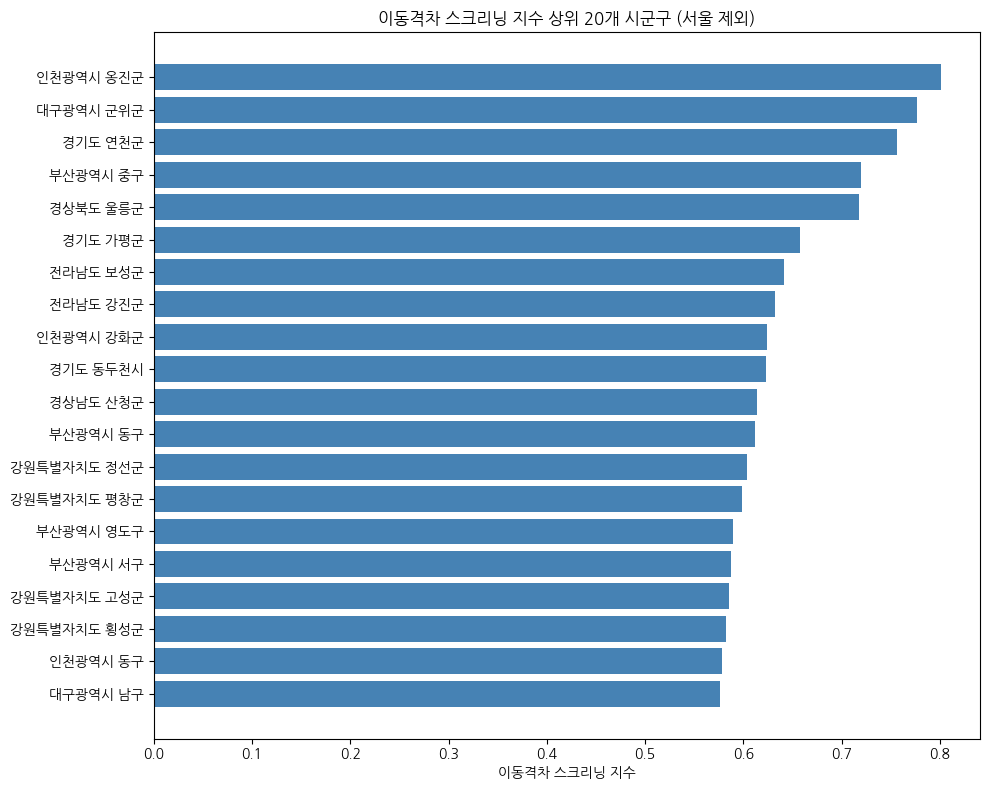

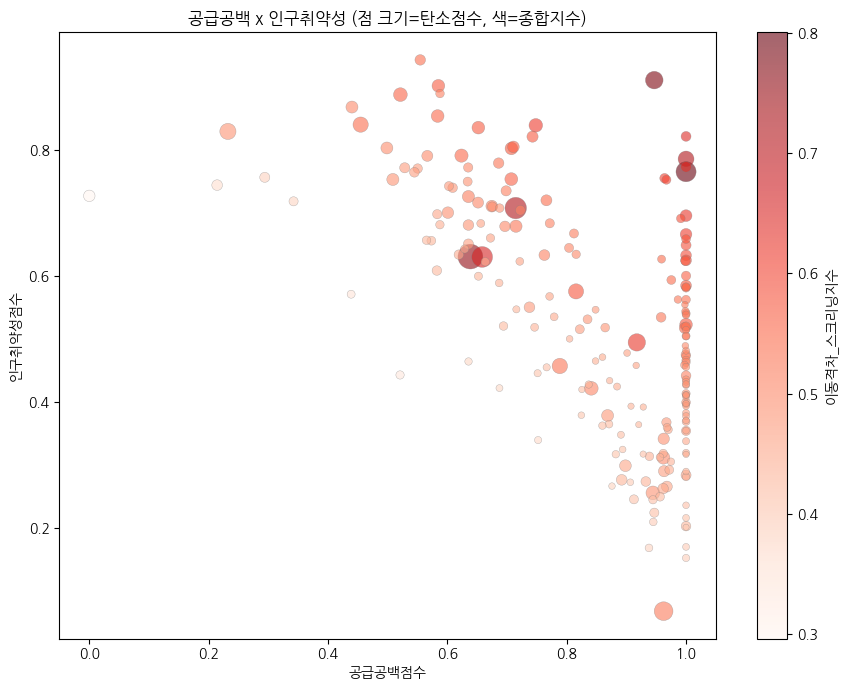

In [53]:
# 8단계: 시각화
!apt-get -qq -y install fonts-nanum

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

fontpath = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(fontpath)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

top20 = result.head(20).sort_values('이동격차_스크리닝지수')

# 1) 상위 20개 지역 막대그래프
plt.figure(figsize=(10, 8))
plt.barh(top20['sigungu'], top20['이동격차_스크리닝지수'], color='steelblue')
plt.xlabel('이동격차 스크리닝 지수')
plt.title('이동격차 스크리닝 지수 상위 20개 시군구 (서울 제외)')
plt.tight_layout()
plt.savefig('top20_bar.png', dpi=150)
plt.show()

# 2) 공급공백 x 인구취약성 산점도 (점 크기 = 탄소점수)
plt.figure(figsize=(9, 7))
sc = plt.scatter(result['공급공백점수'], result['인구취약성점수'],
                  s=result['탄소점수']*300 + 20, alpha=0.6, c=result['이동격차_스크리닝지수'],
                  cmap='Reds', edgecolors='gray', linewidths=0.3)
plt.xlabel('공급공백점수')
plt.ylabel('인구취약성점수')
plt.title('공급공백 x 인구취약성 (점 크기=탄소점수, 색=종합지수)')
plt.colorbar(sc, label='이동격차_스크리닝지수')
plt.tight_layout()
plt.savefig('scatter.png', dpi=150)
plt.show()